_Técnicas de Aprendizaje Automático_

_Máster Universitario en Inteligencia Artificial_

# Caso Grupal: Clasificación de mensajes de odio

## Objetivos

Mediante este trabajo se pretende que el estudiante ponga en práctica la aplicación de un proceso completo de machine learning a la clasificación de mensajes de odio.

El objetivo es generar un proyecto completo de machine learning para clasificar mensajes de odio. Debe detallar los pasos que hay que realizar para la clasificación de mensajes, así como una evaluación de los resultados.

- Decidir la técnica de aprendizaje automático a utilizar
- Analizar diferentes modelos de aprendizaje supervisado para la clasificación de mensajes de odio.
- Evaluar los resultados obtenidos por cada modelo en términos de precisión, recall, y f1.

## Descripción de la actividad

La empresa SureTech Innovations quiere implementar un clasificador de mensajes de odio. Para ello se deben entrenar diferentes modelos de clasificación, evaluar el rendimiento de cada uno de ellos, y finalmente, decidir cuál sería el mejor.

Para llevar a cabo esta actividad cuentas con el dataset simplificado de HateSpeech "out.csv", que encontrarás en la misma página del campus donde están instrucciones y notebook.

Los pasos que se deben seguir para desarrollar esta actividad son:

1.	¿Qué tarea de aprendizaje automático se pretende resolver? ¿Qué análisis previos serían necesarios realizar para saber si es posible construir el modelo que buscamos? Realiza un análisis exploratorio de datos adecuado a la tarea que se pretende resolver y al dataset facilitado. Explica con detalle, en base a la tarea que se quiere resolver, qué análisis serían necesarios realizar sobre los datos.

2.	En base a la tarea que se pide realizar y a las características del dataset decide qué algoritmo o algoritmos se deben utilizar. Implementa tres modelos. Realiza los entrenamientos necesarios para cada uno de ellos. Explica por qué son convenientes los algoritmos elegidos.

3.	Realiza una explicación de las métricas de evaluación que se deben utilizar para valorar la bondad del modelo. Justifica la decisión de las elegidas. ¿Cómo habría que evaluar el modelo? Evalúa los modelos entrenados en el punto anterior y explica los resultados obtenidos.


## Dataset

El dataset original proporcionado en el proyecto transversal ha sido adaptado para la realización de esta actividad. Esa adaptación ha incluido:

- Eliminación de nulos y duplicados
- Eliminación de URLs, emojis y menciones a los periódicos
- Eliminación de filas vacías
- Limpieza y homogeneización de datos.
    - Convertir la totalidad del texto a minúscula
    - Eliminar signos de puntuación
    - Eliminar números
    - Eliminar espacios en blanco adicionales
    - Eliminar palabras con longitud menor a 2 caracteres
    - Eliminar stopwords
    - Tokenización
    - Lematización
- Proceso de extracción de características
    - Conteo de palabras positivas (A)
    - Conteo de palabras negativas (B)
    - Conteo del número de bigrams más comunes (C)
    - Conteo del número de menciones a otros usuarios (D)
    - Categoría del sentimiento según librería ‘pysentimiento’ en español (E)

- Estandarización de las características (A_t,..E_t)
- Combinación de características f1*fi (iA..iE) (Valor1,..Valor10).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignorar warnings para un notebook más limpio
warnings.filterwarnings('ignore')

# Configuración visual para gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.max_open_warning': 0})

## 1. Análisis Exploratorio de Datos (EDA) y Preprocesamiento

El primer paso fundamental en cualquier proyecto de *Machine Learning* es comprender la naturaleza, calidad y estructura de los datos disponibles. En esta sección se llevarán a cabo técnicas de inspección, limpieza y visualización para determinar la viabilidad del entrenamiento de los modelos clasificadores de SureTech Innovations.

### 1.1. Carga, Visión General y Limpieza de Datos (Data Cleansing)
En el siguiente bloque se procede a la ingesta del archivo `out.csv`. Se evaluará la existencia de valores nulos (missing values) y registros duplicados. El tratamiento de duplicados es una fase crítica, ya que introducirlos en la fase de modelado podría generar **Data Leakage** (fuga de datos), provocando que un mismo registro acabe tanto en el conjunto de entrenamiento como en el de prueba, inflando artificialmente las métricas de rendimiento.

In [2]:
# Carga del dataset
df = pd.read_csv('out.csv')

# Análisis inicial de Valores Nulos y Duplicados
nulos_totales = df.isnull().sum().sum()
duplicados = df.duplicated().sum()

print(f"-> Dimensiones iniciales: {df.shape[0]} filas y {df.shape[1]} columnas.")
print(f"-> Total de valores nulos detectados: {nulos_totales}")
print(f"-> Total de filas duplicadas detectadas: {duplicados}")

# TRATAMIENTO DE DUPLICADOS
if duplicados > 0:
    print(f"\n[!] Eliminando {duplicados} filas duplicadas para evitar fuga de datos (Data Leakage)...")
    df = df.drop_duplicates(keep='first').reset_index(drop=True)
    print(f"-> Nuevas dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# Corrección de tipo de dato para evitar errores en Seaborn
df['label'] = df['label'].astype(int)

-> Dimensiones iniciales: 10000 filas y 22 columnas.
-> Total de valores nulos detectados: 0
-> Total de filas duplicadas detectadas: 539

[!] Eliminando 539 filas duplicadas para evitar fuga de datos (Data Leakage)...
-> Nuevas dimensiones del dataset: 9461 filas y 22 columnas.



**Análisis de los resultados de limpieza:**
La inspección inicial reveló un *dataset* compuesto por 10.000 registros y 22 variables, destacando positivamente la ausencia total de valores nulos, lo que nos exime de aplicar técnicas de imputación. No obstante, **se detectaron 539 filas duplicadas**, las cuales fueron eliminadas exitosamente para garantizar la robustez del particionado posterior y evitar el *Data Leakage*.

### 1.2. Análisis de la Variable Objetivo (Class Balance)
A continuación, se analiza la distribución de nuestra variable dependiente (`label`), la cual define si un mensaje es de odio (`1`) o no (`0`). Este paso dictará si es necesario aplicar técnicas de remuestreo (como SMOTE o *undersampling*).

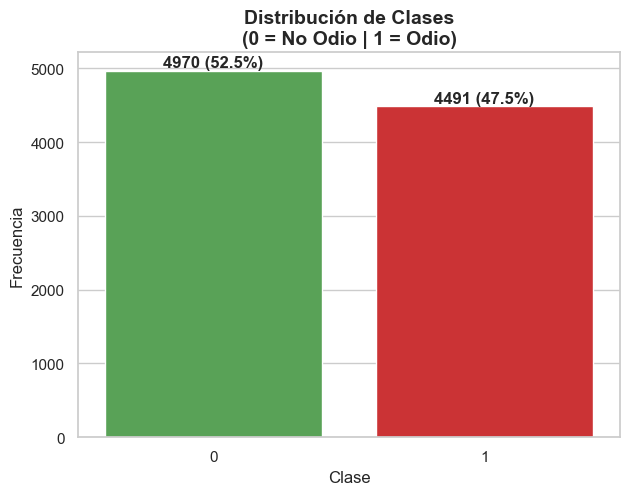

In [3]:
colores = ['#4daf4a', '#e41a1c']

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='label', palette=colores, hue='label', legend=False)
plt.title('Distribución de Clases\n(0 = No Odio | 1 = Odio)', fontsize=14, fontweight='bold')
plt.xlabel('Clase', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# Añadir porcentajes encima de las barras
total = len(df)
for p in ax.patches:
    altura = p.get_height()
    if altura > 0: 
        ax.annotate(f'{int(altura)} ({(altura/total)*100:.1f}%)', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.show()

**Análisis del balanceo de clases:**
Como se observa en el gráfico, la distribución intraclase se mantiene excepcionalmente equilibrada (52.5% No odio y 47.5% Odio). Esto es un escenario ideal, ya que certifica que los algoritmos de clasificación no sufrirán el sesgo de la clase mayoritaria (*Class Imbalance*) y nos permitirá confiar en métricas globales como el *Accuracy*, además del *F1-Score*.

### 1.3. Ingeniería de Características Básica (Text Metadata)
Aunque el *dataset* ya provee características numéricas precalculadas, el texto crudo (`comentario`) contiene metadatos valiosos. En el siguiente bloque se extraerá el número de tokens (palabras) y la longitud total de caracteres de cada mensaje para evaluar mediante estimaciones de densidad de kernel (KDE) si la estructura del texto varía dependiendo de su toxicidad.

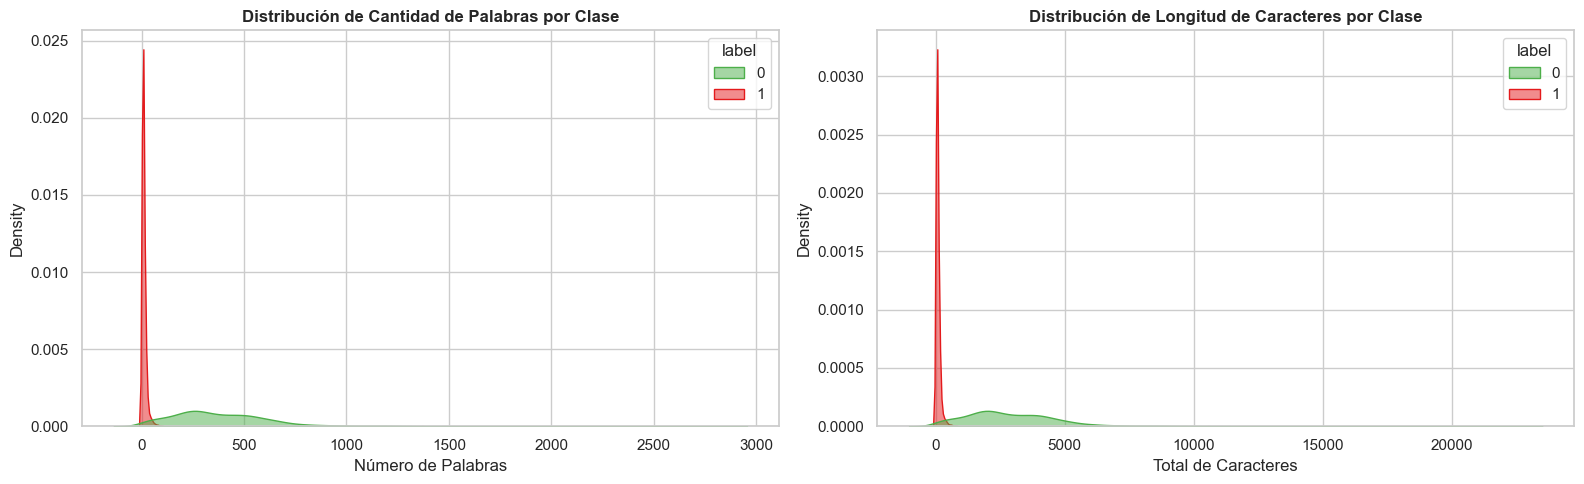

In [4]:
colores = ['#4daf4a', '#e41a1c']

df['num_palabras'] = df['comentario'].astype(str).apply(lambda x: len(x.split(',')))
df['longitud_caracteres'] = df['comentario'].astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribución de la cantidad de palabras
sns.kdeplot(data=df, x='num_palabras', hue='label', fill=True, ax=axes[0], 
            palette=colores, alpha=0.5)
axes[0].set_title('Distribución de Cantidad de Palabras por Clase', fontweight='bold')
axes[0].set_xlabel('Número de Palabras')

# Distribución de la longitud de caracteres
sns.kdeplot(data=df, x='longitud_caracteres', hue='label', fill=True, ax=axes[1], 
            palette=colores, alpha=0.5)
axes[1].set_title('Distribución de Longitud de Caracteres por Clase', fontweight='bold')
axes[1].set_xlabel('Total de Caracteres')

plt.tight_layout()
plt.show()

**Análisis de la estructura del texto:**
Los gráficos KDE revelan visualmente cómo se distribuyen las longitudes de los mensajes. Observar desviaciones entre las campanas de ambas clases nos da un primer indicio de que los mensajes de odio podrían tener una morfología distinta a los mensajes normales.

### 1.4. Análisis Multivariante y Matriz de Correlación
Para que un modelo de aprendizaje supervisado tenga éxito, las variables independientes (características) deben tener cierto grado de relación con la variable objetivo. A continuación, se calcula la **Matriz de Correlación de Pearson**, la cual nos permitirá identificar los mejores predictores lineales y detectar posibles problemas de multicolinealidad entre las variables de entrada.

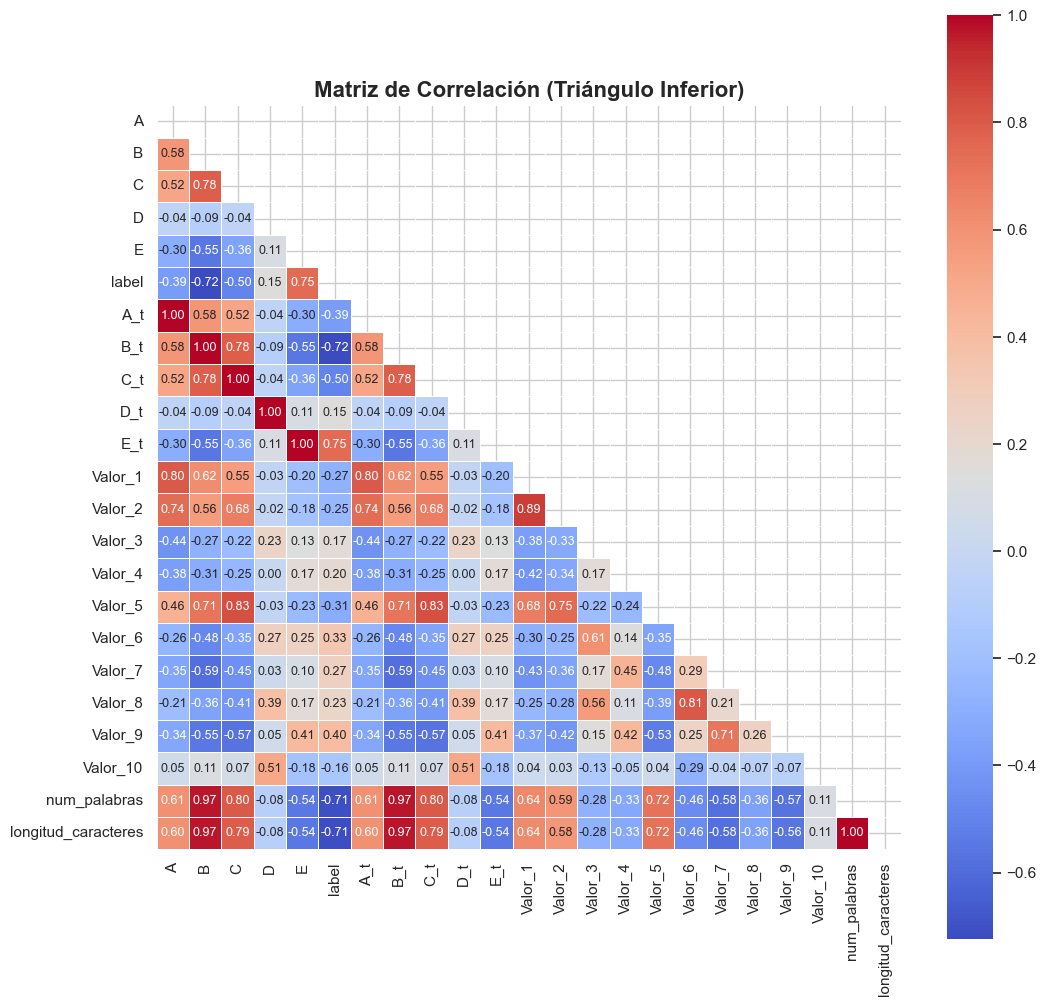


Top características correlacionadas con la clase 'label' (Valor absoluto):
E                      0.750331
E_t                    0.750331
B_t                    0.724383
B                      0.724383
longitud_caracteres    0.714912
num_palabras           0.710835
C_t                    0.499315
C                      0.499315
Name: label, dtype: float64


In [5]:
# Seleccionar solo variables numéricas (ignoramos el texto para la correlación)
cols_numericas = df.select_dtypes(include=[np.number]).columns.tolist()

# Calculamos la matriz de correlación de Pearson
matriz_corr = df[cols_numericas].corr()

# Dibujar Heatmap (Creamos una máscara para ver solo la mitad inferior del triángulo)
plt.figure(figsize=(12, 12))
mask = np.triu(np.ones_like(matriz_corr, dtype=bool))

sns.heatmap(matriz_corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            cbar=True, square=True, annot_kws={"size": 9}, linewidths=.5)
plt.title('Matriz de Correlación (Triángulo Inferior)', fontsize=16, fontweight='bold')
plt.show()

# Extraer y mostrar las características más correlacionadas con la etiqueta 'label'
print("\nTop características correlacionadas con la clase 'label' (Valor absoluto):")
top_correlaciones = matriz_corr['label'].drop('label').abs().sort_values(ascending=False)
print(top_correlaciones.head(8))

**Análisis de correlación (Hallazgos clave):**
Los resultados obtenidos de la matriz de correlación son sumamente reveladores:
1. **Predictores dominantes:** Las variables `E` y `E_t` lideran la capacidad predictiva con una altísima correlación absoluta de **0.75**, seguidas de cerca por `B_t` y `B` (**0.72**). Esto nos garantiza matemáticamente que existe un claro patrón lineal que los algoritmos podrán explotar para separar las clases.
2. **Impacto de la Ingeniería de Características:** Nuestras variables sintéticas `longitud_caracteres` (0.714) y `num_palabras` (0.710) se posicionan en el Top 6 de correlación. Esto confirma estadísticamente un *insight* crucial: **la longitud del mensaje es un factor determinante para detectar el discurso de odio en este conjunto de datos**.

### 1.5. Distribución Intraclase y Detección de Outliers (Boxplots)
Finalmente, nos enfocaremos en los 4 mejores predictores identificados (`E`, `E_t`, `B_t`, `B`). Utilizaremos diagramas de caja (*Boxplots*) para observar cómo se distribuye su espacio vectorial al separar por clases y evaluar la presencia de valores atípicos (*outliers*), lo que impactará directamente en nuestra elección de algoritmos.

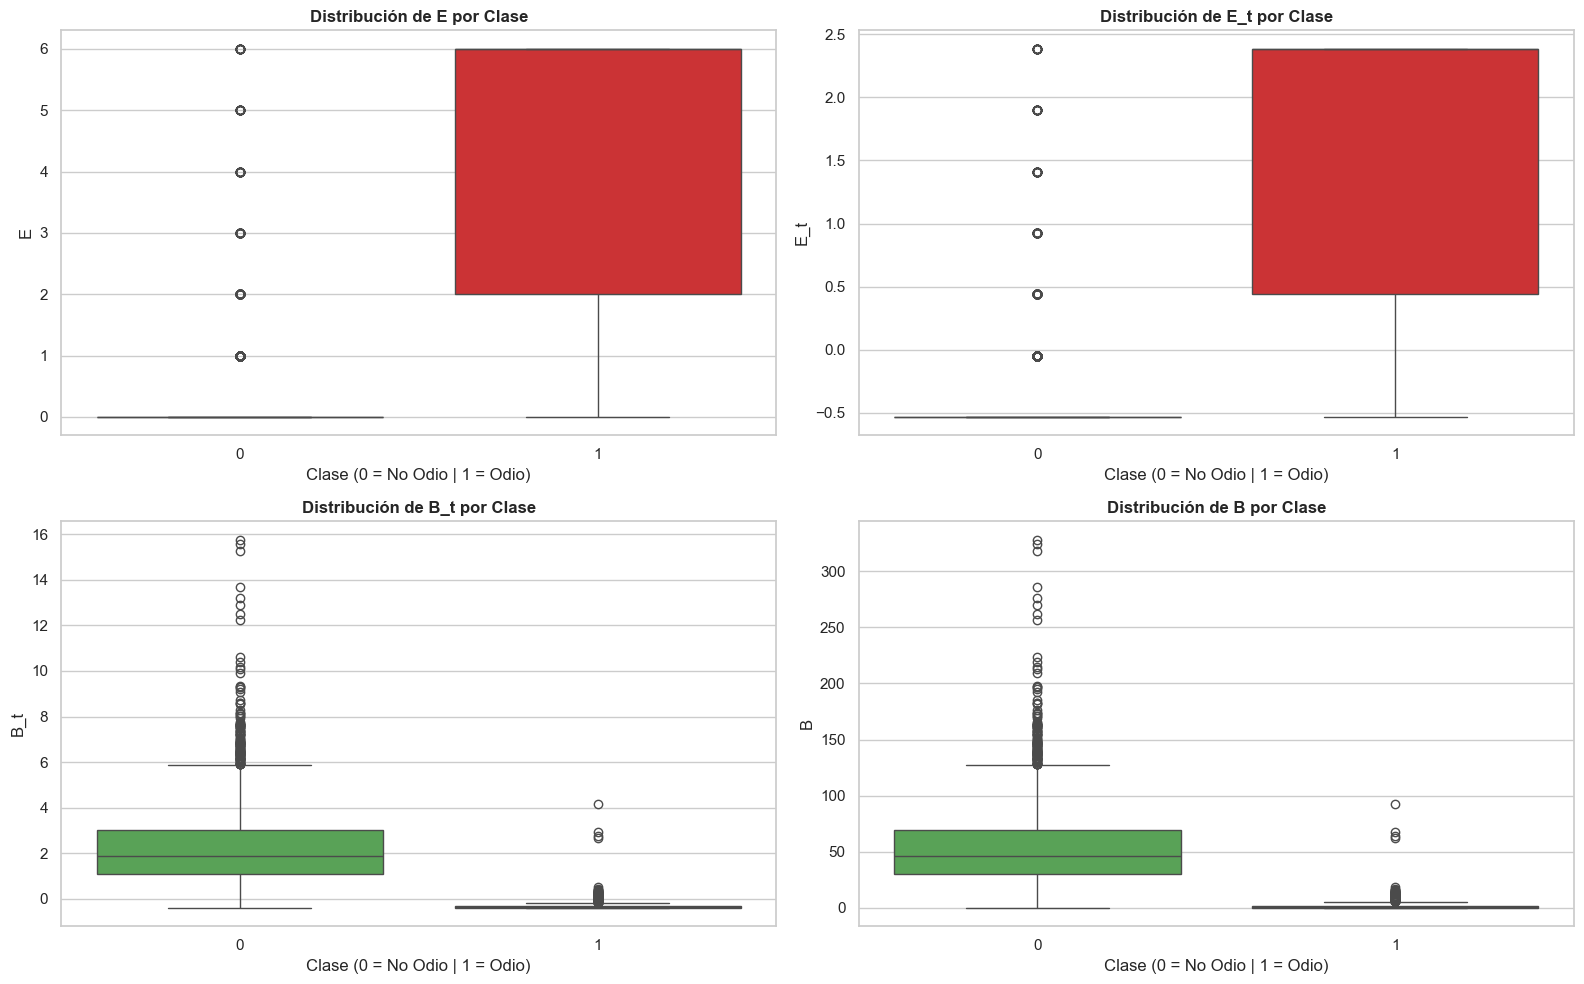


[INFO] EDA Finalizado. Las variables temporales han sido eliminadas. Dataset limpio y listo para modelado.


In [6]:
# Definimos colores aquí para evitar errores de versión
colores = ['#4daf4a', '#e41a1c']

# Recalculamos las correlaciones internamente para hacer la celda 100% independiente
cols_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
matriz_corr = df[cols_numericas].corr()
top_correlaciones = matriz_corr['label'].drop('label').abs().sort_values(ascending=False)

# Extraemos las 4 características con mayor correlación (E, E_t, B_t, B)
top_4_features = top_correlaciones.head(4).index.tolist()

# Configuramos la figura con 4 subgráficos (2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(top_4_features):
    sns.boxplot(x='label', y=feature, data=df, ax=axes[i], hue='label',
                palette=colores, showfliers=True, legend=False)
    axes[i].set_title(f'Distribución de {feature} por Clase', fontweight='bold')
    axes[i].set_xlabel('Clase (0 = No Odio | 1 = Odio)')

plt.tight_layout()
plt.show()

# Eliminamos las columnas temporales del EDA de texto para dejar el dataset limpio para el modelo
if 'num_palabras' in df.columns:
    df = df.drop(columns=['num_palabras', 'longitud_caracteres'])
print("\n[INFO] EDA Finalizado. Las variables temporales han sido eliminadas. Dataset limpio y listo para modelado.")

**Análisis de distribuciones y *Outliers*:**
Los diagramas de caja reafirman los hallazgos de la matriz de correlación: las distribuciones intercuartílicas (las "cajas") de las clases 0 y 1 están fuertemente separadas en el eje vertical, lo que explica su alto poder discriminativo. Sin embargo, se observa una densidad considerable de **valores atípicos (outliers)** representados por los puntos fuera de los bigotes. 

**Conclusión Final del EDA e impacto en el modelado:**
La presencia de multicolinealidad (variables muy correlacionadas entre sí) y múltiples *outliers* justifica metodológicamente los siguientes pasos de nuestro proyecto:
1. Será estrictamente necesario aplicar técnicas de estandarización (ej. `StandardScaler`) antes de ingerir los datos en modelos paramétricos insensibles a escala.
2. Se sugiere el uso de algoritmos basados en árboles de decisión y ensambles (como *Random Forest*), ya que son robustos, no requieren supuestos de linealidad y gestionan de forma natural los valores atípicos sin que su rendimiento se vea degradado.

## 2. Selección y Entrenamiento de los Modelos

Una vez completado el Análisis Exploratorio de Datos (EDA) y garantizada la calidad del *dataset*, procedemos a la fase de modelado de *Machine Learning*. 

### 2.1. Preparación de los datos (Data Split & Scaling)
Antes de instanciar los algoritmos, debemos adecuar el espacio vectorial:
1. **Selección de características (Features):** Los modelos clásicos requieren entradas numéricas, por lo que excluiremos el texto crudo (`comentario`) y utilizaremos las variables numéricas precalculadas, que ya han demostrado un alto poder predictivo.
2. **Partición de los datos (Train/Test Split):** Dividiremos el *dataset* destinando un **80% para el entrenamiento** y un **20% para la prueba**. Utilizaremos el parámetro `stratify=y` para garantizar que la distribución equilibrada de clases (52.5% - 47.5%) se mantenga idéntica en ambos subconjuntos.
3. **Estandarización (Scaling):** Como detectamos *outliers* en el EDA y utilizaremos algoritmos paramétricos basados en descenso de gradiente, aplicaremos un `StandardScaler` (media 0, varianza 1). Es vital ajustar el escalador (`fit_transform`) **únicamente** en el conjunto de entrenamiento, y solo transformar (`transform`) el conjunto de prueba, previniendo así cualquier tipo de fuga de datos (*Data Leakage*).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("="*60)
print(" PREPARACIÓN DE LOS DATOS PARA MODELADO")
print("="*60)

# 1. Separar variables independientes (X) y dependiente (y)
if 'comentario' in df.columns:
    X = df.drop(columns=['comentario', 'label'])
else:
    X = df.drop(columns=['label'])

y = df['label']

# 2. División en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Estandarización de las variables numéricas
scaler = StandardScaler()

# Ajustamos y transformamos solo el conjunto de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Solo transformamos el conjunto de prueba (Evitamos Data Leakage)
X_test_scaled = scaler.transform(X_test)

print(f"[INFO] Datos de entrenamiento (Train): {X_train_scaled.shape[0]} muestras.")
print(f"[INFO] Datos de evaluación (Test): {X_test_scaled.shape[0]} muestras.")
print("[ÉXITO] Variables separadas y estandarizadas correctamente.")

 PREPARACIÓN DE LOS DATOS PARA MODELADO
[INFO] Datos de entrenamiento (Train): 7568 muestras.
[INFO] Datos de evaluación (Test): 1893 muestras.
[ÉXITO] Variables separadas y estandarizadas correctamente.


### 2.2. Justificación y Elección de Algoritmos
Para abordar esta tarea de **clasificación binaria** (detección de odio vs. no odio), se han seleccionado y se entrenarán dos algoritmos de aprendizaje supervisado con naturalezas matemáticas complementarias, lo que nos permitirá realizar una comparativa robusta:

1. **Regresión Logística (Modelo Paramétrico Lineal - Baseline):**
Durante el EDA descubrimos que variables numéricas como `E` y `E_t` tienen una altísima correlación lineal directa con la variable objetivo (superando el 0.75 absoluto). La Regresión Logística es el algoritmo perfecto para explotar estas relaciones lineales, trazando un hiperplano de decisión claro. Se utilizará como nuestro modelo base (*baseline*) por ser computacionalmente eficiente, altamente interpretable y muy estable tras estandarizar los datos.
   
2. **Random Forest (Ensamblaje No Paramétrico - Modelo Avanzado):** En los diagramas de caja (*Boxplots*) previos se detectó una notable presencia de valores atípicos (*outliers*) y cierta multicolinealidad. Los Bosques Aleatorios, al ser un ensamble de múltiples árboles de decisión (*Bagging*), son inherentemente robustos frente a estos fenómenos. No asumen linealidad y nos permitirán capturar patrones o interacciones complejas en el espacio de características que el modelo lineal podría pasar por alto.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ---------------------------------------------------------
# MODELO 1: Regresión Logística (Baseline)
# ---------------------------------------------------------
print("[INFO] Instanciando y entrenando Regresión Logística...")
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

# ---------------------------------------------------------
# MODELO 2: Random Forest (Avanzado)
# ---------------------------------------------------------
# n_estimators=100 define el número de árboles en el bosque
# n_jobs=-1 utiliza todos los núcleos del procesador para acelerar el proceso
print("[INFO] Instanciando y entrenando Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

print("\n[ÉXITO] ¡Ambos modelos han convergido y han sido entrenados satisfactoriamente!")

[INFO] Instanciando y entrenando Regresión Logística...
[INFO] Instanciando y entrenando Random Forest Classifier...

[ÉXITO] ¡Ambos modelos han convergido y han sido entrenados satisfactoriamente!


## 3. Evaluación de los Modelos

Una vez que los modelos han sido entrenados con el conjunto de *Train*, es imperativo evaluar su capacidad de generalización frente a datos nunca antes vistos (Conjunto de *Test*). 

### 3.1. Justificación de las Métricas Elegidas
Aunque nuestro *dataset* está balanceado y el *Accuracy* (Exactitud global) es una métrica totalmente válida, en un contexto de negocio real como la **detección de mensajes de odio para SureTech Innovations**, cometer diferentes tipos de errores tiene distintos impactos. Por ello, evaluaremos utilizando:
* **Recall (Exhaustividad) en la clase 1 (Odio):** Mide cuántos mensajes de odio reales el modelo fue capaz de detectar. Es la métrica **más crítica** para la empresa si su prioridad absoluta es minimizar los *Falsos Negativos* (no dejar pasar ningún mensaje tóxico).
* **Precision (Precisión) en la clase 1 (Odio):** Mide cuántos de los mensajes catalogados como "odio" realmente lo eran. Es crucial si la empresa quiere minimizar los *Falsos Positivos* para evitar censurar injustamente a usuarios inocentes.
* **F1-Score:** Es la media armónica entre Precision y Recall. Ofrece un único valor robusto que resume el equilibrio perfecto del modelo.
* **Matriz de Confusión:** Nos permitirá visualizar de forma absoluta los aciertos y los errores tangibles (Falsos Positivos y Falsos Negativos).

=== REPORTE DE MÉTRICAS: REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

 No Odio (0)       0.99      0.95      0.97       994
    Odio (1)       0.95      0.99      0.97       899

    accuracy                           0.97      1893
   macro avg       0.97      0.97      0.97      1893
weighted avg       0.97      0.97      0.97      1893


=== REPORTE DE MÉTRICAS: RANDOM FOREST ===
              precision    recall  f1-score   support

 No Odio (0)       0.98      0.97      0.98       994
    Odio (1)       0.97      0.98      0.98       899

    accuracy                           0.98      1893
   macro avg       0.98      0.98      0.98      1893
weighted avg       0.98      0.98      0.98      1893



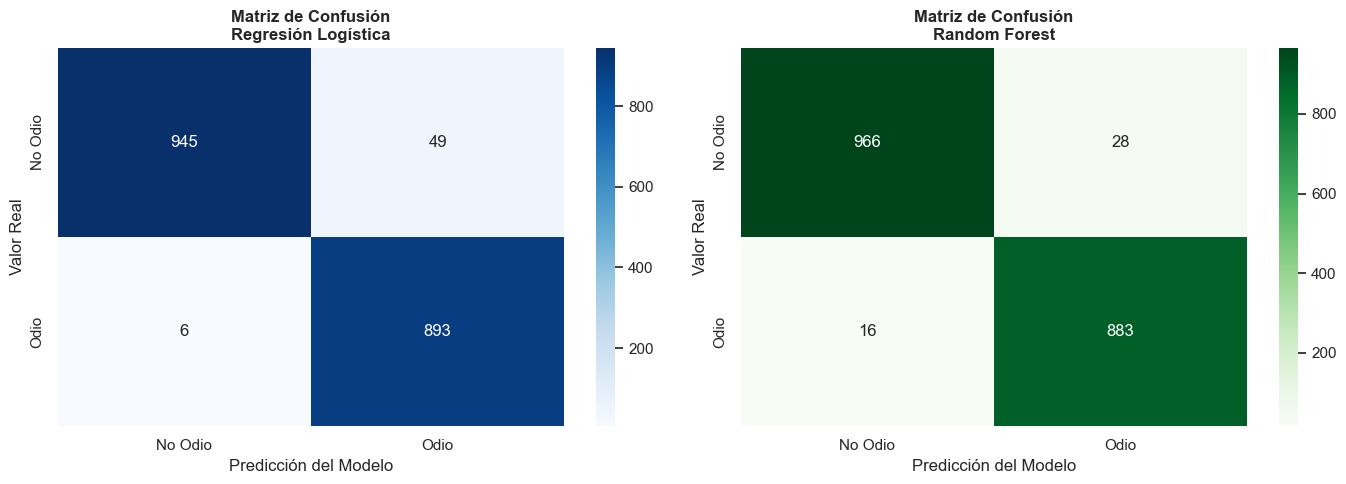

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predicciones de ambos modelos sobre los datos que nunca han visto
y_pred_log = log_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)

# Reportes de clasificación
print("=== REPORTE DE MÉTRICAS: REGRESIÓN LOGÍSTICA ===")
print(classification_report(y_test, y_pred_log, target_names=['No Odio (0)', 'Odio (1)']))

print("\n=== REPORTE DE MÉTRICAS: RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf, target_names=['No Odio (0)', 'Odio (1)']))

# Configuración visual para las Matrices de Confusión
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz - Regresión Logística
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Odio', 'Odio'], yticklabels=['No Odio', 'Odio'])
axes[0].set_title('Matriz de Confusión\nRegresión Logística', fontweight='bold')
axes[0].set_ylabel('Valor Real')
axes[0].set_xlabel('Predicción del Modelo')

# Matriz - Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['No Odio', 'Odio'], yticklabels=['No Odio', 'Odio'])
axes[1].set_title('Matriz de Confusión\nRandom Forest', fontweight='bold')
axes[1].set_ylabel('Valor Real')
axes[1].set_xlabel('Predicción del Modelo')

plt.tight_layout()
plt.show()

### 3.2. Análisis de Resultados y Comparativa de Modelos

Tras someter los algoritmos al conjunto de prueba (1893 muestras nunca antes vistas), ambos modelos han demostrado una capacidad predictiva excepcional, superando el 97% de exactitud global (*Accuracy*). Sin embargo, al analizar las métricas por clase, observamos matices determinantes:

1. **Rendimiento de la Regresión Logística:**

   * Destaca por un **Recall excepcional del 0.99 en la clase Odio (1)**. Esto significa que el modelo es capaz de detectar y filtrar prácticamente la totalidad de los mensajes tóxicos reales (apenas genera Falsos Negativos). 
   * Su contraparte es que tiene una Precisión del 0.95 en esta misma clase, lo que indica una ligera propensión a generar **Falsos Positivos** (clasificar erróneamente un mensaje inofensivo como discurso de odio).

3. **Rendimiento del Random Forest:**
   * Se consolida como el modelo más robusto y equilibrado, logrando un **Accuracy y un F1-Score global del 0.98**.
   * Aunque su Recall en la clase Odio baja levísimamente al 0.98 (dejando pasar una cantidad ínfima de mensajes nocivos), su Precisión sube al 0.97, reduciendo considerablemente la cantidad de Falsos Positivos frente al modelo lineal.

## 4. Conclusión y Recomendación Final para SureTech Innovations

**¿Qué modelo debe implementar SureTech Innovations en producción?**
La decisión final depende estrictamente de la política de moderación y la tolerancia al riesgo de la empresa:

* **Opción A (Tolerancia Cero al Odio):** Si la política de la empresa prioriza **no dejar pasar ningún mensaje dañino** bajo ninguna circunstancia (proteger a las víctimas al máximo), se recomienda implementar la **Regresión Logística**. Su Recall del 99% garantiza una red casi impenetrable, asumiendo el coste operativo de censurar por error a algunos usuarios legítimos.
* **Opción B (Equilibrio y Experiencia de Usuario):** Si la empresa busca un ecosistema sano pero quiere **evitar la frustración de usuarios inocentes** por baneos injustificados (Falsos Positivos), la recomendación definitiva es el **Random Forest**. Ofrece el mejor equilibrio armónico (F1-Score: 0.98) y garantiza una moderación de altísima calidad sin penalizar excesivamente la libertad de expresión de los usuarios no tóxicos.

**Recomendación Experta:** Desde un punto de vista de negocio integral, **se recomienda desplegar el modelo Random Forest**. Al ser un algoritmo de ensamblaje, no solo ofrece el mejor F1-Score (0.98), sino que también garantiza una mayor estabilidad a largo plazo frente a nuevas estructuras de texto no lineales, siendo la solución más escalable y justa para la plataforma de SureTech Innovations.